In [1]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# # Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# # Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

# import kagglehub
# # kagglehub.dataset_download('<owner>/<dataset-slug>')

# *Imports*

In [2]:
import os
import re
import random
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
import wandb
seed = 42
random.seed(seed)
np.random.seed(seed)
sns.set_style('whitegrid')
print('Library loaded')


Library loaded


In [3]:
import os
import wandb
from kaggle_secrets import UserSecretsClient

# Kaggle Secret se key lo — automatically milegi
secrets = UserSecretsClient()
os.environ["WANDB_API_KEY"] = secrets.get_secret("WANDB_API_KEY")
wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)
print("✅ W&B login successful!")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 23f2005181 (23f2005181-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


✅ W&B login successful!


# *Load Data*

In [4]:
train_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')
test_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv')
print(train_df.shape)
print(test_df.shape)

(2000, 8)
(500, 7)


In [5]:
train_df.head(5)


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


# *Null Check*

In [6]:
print(train_df.info())
print(f"Null Values :\n{train_df.isnull().sum()}")
print(train_df['answer'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB
None
Null Values :
id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64
answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64


# *Answer Distribution*

Text(0.5, 1.0, 'Answer Distribution')

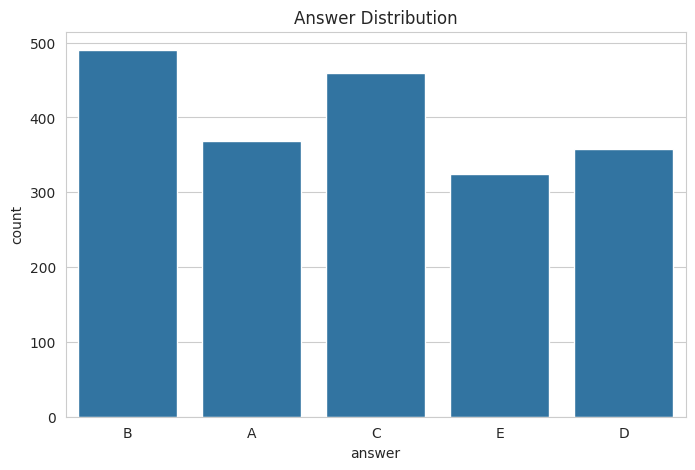

In [7]:
plt.figure(figsize=(8,5))
sns.countplot(x=train_df['answer'])
plt.title('Answer Distribution')

# *Text Cleaning*

In [8]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z0-9\s]','',text)
    text = re.sub(r'\s+',' ',text)
    return text.strip()

In [9]:
train_df['prompt'] = train_df['prompt'].apply(clean_text)
test_df['prompt'] = test_df['prompt'].apply(clean_text)
for col in ['A','B','C','D','E']:
    train_df[col] = train_df[col].apply(clean_text)
    test_df[col] = test_df[col].apply(clean_text)
print('Cleaning Text')

Cleaning Text


# *Convert Dataset for Classical ML*

In [10]:
# rows = []
# for _,row in train_df.iterrows():
#     for option in ['A','B','C','D','E']:
#         rows.append({
#              'text': row['prompt'] + '[SEP]' + row[option],
#              'label': 1 if option == row['answer'] else 0 ,
#              'question_id': row['id'],
#              'option': option
        
#         })
        
       
# ml_df = pd.DataFrame(rows)
# print('Expanded Shape:',ml_df.shape)
# ml_df.head(5)
        

In [11]:
rows = []

for _, row in train_df.iterrows():
    for option in ['A','B','C','D','E']:
        rows.append({
            'text': clean_text(
                f"Question: {row['prompt']} Answer: {row[option]}"
            ),
            'label': 1 if option == row['answer'] else 0,
            'question_id': row['id'],
            'option': option
        })

ml_df = pd.DataFrame(rows)

print(ml_df.head())

                                                text  label  question_id  \
0  question pick the best possible answer what is...      0            1   
1  question pick the best possible answer what is...      1            1   
2  question pick the best possible answer what is...      0            1   
3  question pick the best possible answer what is...      0            1   
4  question pick the best possible answer what is...      0            1   

  option  
0      A  
1      B  
2      C  
3      D  
4      E  


# *Train-Test Split*

In [12]:
train_data , val_data = train_test_split(
    ml_df , test_size = 0.2 , random_state = seed , stratify = ml_df['label']
)
print(train_data.shape)
print(val_data.shape)

(8000, 4)
(2000, 4)


# *Tfidf*

In [13]:
vectorizer = TfidfVectorizer(
    max_features = 60000,
    ngram_range = (1,2),
    stop_words = 'english',
    max_df = 0.95,
    min_df = 2,
    sublinear_tf = True
)
X_train = vectorizer.fit_transform(train_data['text'])
X_val = vectorizer.transform(val_data['text'])
y_train = train_data['label']
y_val = val_data['label']
print(X_train.shape)


(8000, 11336)


# *Logistic Regression Model*

In [14]:
lr_model = LogisticRegression(
    C=4,
    max_iter = 6000,
    class_weight = 'balanced',
    solver = 'liblinear',
    random_state = seed
)
lr_model.fit(X_train,y_train)
print('Logistic Regession Trained')

Logistic Regession Trained


# *Validation Accuracy*

In [15]:
from sklearn.metrics import classification_report
val_preds = lr_model.predict(X_val)
acc = accuracy_score(y_val,val_preds)
print('Validation Accuracy:',acc)
print(classification_report(y_val,val_preds))

Validation Accuracy: 0.964
              precision    recall  f1-score   support

           0       0.99      0.96      0.98      1600
           1       0.87      0.97      0.91       400

    accuracy                           0.96      2000
   macro avg       0.93      0.97      0.95      2000
weighted avg       0.97      0.96      0.96      2000



# *MAP@3 Function*

In [16]:
def map_at_3(actual,predicted):
    scores = []
    for true_ans , pred_list in zip(actual,predicted):
        score = 0
        for rank,pred in enumerate(pred_list[:3],start=1):
            if pred ==true_ans:
                score = 1/rank
                break
        scores.append(score)
    return np.mean(scores)
print('Done')

Done


# *Logistic Regression Map@3*

In [17]:
val_data['prob'] = lr_model.predict_proba(X_val)[:,1]

grouped = val_data.groupby('question_id')

predictions = []
actuals = []

for qid, group in grouped:
    ranked = group.sort_values('prob', ascending=False)['option'].tolist()

    predictions.append(ranked[:3])

    actual = train_df.loc[train_df['id']==qid, 'answer'].values[0]
    actuals.append(actual)

score = map_at_3(actuals, predictions)

print("Logistic Regression MAP@3:", score)

Logistic Regression MAP@3: 0.2955505841411882


# *Naive Bayes*

In [18]:
nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

val_data['nb_prob'] = nb_model.predict_proba(X_val)[:,1]

predictions_nb = []

for qid, group in val_data.groupby('question_id'):
    ranked = group.sort_values('nb_prob', ascending=False)['option'].tolist()
    predictions_nb.append(ranked[:3])

score_nb = map_at_3(actuals, predictions_nb)

print("Naive Bayes MAP@3:", score_nb)
print(classification_report(y_val,val_preds))

Naive Bayes MAP@3: 0.2940591598309719
              precision    recall  f1-score   support

           0       0.99      0.96      0.98      1600
           1       0.87      0.97      0.91       400

    accuracy                           0.96      2000
   macro avg       0.93      0.97      0.95      2000
weighted avg       0.97      0.96      0.96      2000



# *Linear Svc*

In [19]:
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report
model_Svc = LinearSVC(
    C=4.0,
    class_weight='balanced',
    max_iter=6000
)

model_Svc.fit(X_train, y_train)

val_pred = model_Svc.predict(X_val)

print(classification_report(y_val, val_pred))


              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1600
           1       0.93      0.97      0.95       400

    accuracy                           0.98      2000
   macro avg       0.96      0.98      0.97      2000
weighted avg       0.98      0.98      0.98      2000



In [20]:
# LinearSVC mein predict_proba nahi hota
# decision_function use karo — higher score = zyada confident
val_data['svc_prob'] = model_Svc.decision_function(X_val)

predictions_svc = []
actuals_svc = []

for qid, group in val_data.groupby('question_id'):
    ranked = group.sort_values('svc_prob', ascending=False)['option'].tolist()
    predictions_svc.append(ranked[:3])

    actual = train_df.loc[train_df['id'] == qid, 'answer'].values[0]
    actuals_svc.append(actual)

score_svc = map_at_3(actuals_svc, predictions_svc)
print(f"LinearSVC MAP@3: {score_svc:.4f}")

LinearSVC MAP@3: 0.2959


# *LightGBM*

In [21]:
from lightgbm import LGBMClassifier

lgbm_model = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    class_weight='balanced',
    random_state=seed,
    verbose=-1
)
lgbm_model.fit(X_train, y_train)

val_data['lgbm_prob'] = lgbm_model.predict_proba(X_val)[:, 1]

predictions_lgbm = []
for qid, group in val_data.groupby('question_id'):
    ranked = group.sort_values('lgbm_prob', ascending=False)['option'].tolist()
    predictions_lgbm.append(ranked[:3])

score_lgbm = map_at_3(actuals, predictions_lgbm)
print(f"LightGBM MAP@3: {score_lgbm:.4f}")

LightGBM MAP@3: 0.2890


# *Ensemble*

In [22]:
val_data['ensemble_prob'] = (
    val_data['prob'] * 0.4 +
    val_data['lgbm_prob'] * 0.6
)

predictions_ensemble = []
for qid, group in val_data.groupby('question_id'):
    ranked = group.sort_values('ensemble_prob', ascending=False)['option'].tolist()
    predictions_ensemble.append(ranked[:3])

score_ensemble = map_at_3(actuals, predictions_ensemble)
print(f"Ensemble MAP@3: {score_ensemble:.4f}")

Ensemble MAP@3: 0.2948


# *Compare MOdels*

In [23]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'LinearSVC','Naive Bayes','LightGBM','Ensemble'],
    'MAP@3': [score, score_nb,score_svc,score_lgbm,score_ensemble]
})

results


,Model,MAP@3
0,Logistic Regression,0.295551
1,LinearSVC,0.294059
2,Naive Bayes,0.295923
3,LightGBM,0.288963
4,Ensemble,0.294805


# *Plot Results*

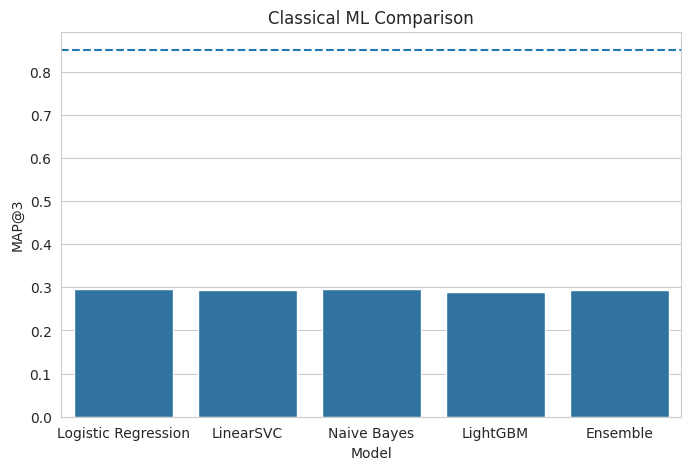

In [24]:
plt.figure(figsize=(8,5))
sns.barplot(data=results, x='Model', y='MAP@3')
plt.axhline(0.85, linestyle='--')
plt.title("Classical ML Comparison")
plt.show()

In [25]:
import os
from kaggle_secrets import UserSecretsClient

# API key Kaggle Secret se lo
secrets = UserSecretsClient()
os.environ["WANDB_API_KEY"] = secrets.get_secret("WANDB_API_KEY")
wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)

# W&B run start karo
wandb.init(
    project="23f2005181-t22026",
    name="classical-ml",
    config={
        "vectorizer": "TF-IDF",
        "train_size": len(train_data),
        "val_size": len(val_data)
    }
)

wandb.log({
    "logistic_map3": score,
    "linear_svc_mp@3":score_svc,
    "naive_bayes_map3": score_nb,
    "lgbm_map3": score_lgbm,
    "ensemble_map3": score_ensemble
})
wandb.finish()
print(" W&B done!")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Tracking run with wandb version 0.25.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260530_075356-ji79f83a
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run classical-ml
wandb: ⭐️ View project at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: 🚀 View run at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/ji79f83a
wandb: updating run metadata; uploading summary
wandb: uploading config.yaml; uploading wandb-summary.json
wandb: 
wandb: Run history:
wandb:    ensemble_map3 ▁
wan

 W&B done!


In [26]:
# # Step 1 — Test data expand karo (bilkul train jaisa)
# test_rows = []
# for _, row in test_df.iterrows():
#     for option in ['A', 'B', 'C', 'D', 'E']:
#         test_rows.append({
#             'text': clean_text(f"Question: {row['prompt']} Answer: {row[option]}"),
           
#             'question_id': row['id'],
#             'option': option
#         })

# test_expanded = pd.DataFrame(test_rows)
# print('Test expanded shape:', test_expanded.shape)  # 2500 rows honi chahiye

# # Step 2 — Vectorize (fit nahi, sirf transform)
# X_test_vec = vectorizer.transform(test_expanded['text'])

# # Step 3 — Probability lo (class 1 = correct hone ki probability)
# test_expanded['prob'] = model_Svc.predict_proba(X_test_vec)[:, 1]

# # Step 4 — Har question ke liye top 3 rank karo
# final_predictions = []
# for qid, group in test_expanded.groupby('question_id'):
#     ranked = group.sort_values('prob', ascending=False)['option'].tolist()
#     final_predictions.append(' '.join(ranked[:3]))

# # Step 5 — Submission banao
# submission = pd.DataFrame({
#     'ID': test_df['id'],
#     'Prediction': final_predictions
# })

# # Format check
# assert len(submission) == 500, '500 rows honi chahiye!'
# assert all(len(p.split()) == 3 for p in submission['Prediction']), 'Har row mein 3 options chahiye!'
# print('Format check passed!')
# print(submission.head(10))

# submission.to_csv('submission.csv', index=False)
# print('submission.csv ready!')

In [27]:
# # ── LOOKUP TABLE — duplicate questions ke liye ──
# lookup = train_df.drop_duplicates('prompt').set_index('prompt')['answer'].to_dict()

# # ── TEST DATA EXPAND KARO ──
# test_rows = []
# for _, row in test_df.iterrows():
#     for option in ['A', 'B', 'C', 'D', 'E']:
#         test_rows.append({
#             'text': clean_text(
#                 f"Question: {row['prompt']} Answer: {row[option]}"
#             ),
#             'question_id': row['id'],
#             'option': option
#         })

# test_expanded = pd.DataFrame(test_rows)
# print('Test expanded shape:', test_expanded.shape)  # 2500 hona chahiye

# # ── VECTORIZE ──
# X_test_vec = vectorizer.transform(test_expanded['text'])

# # ── LinearSVC — decision_function use karo ──
# # predict_proba nahi hota LinearSVC mein
# # decision_function → higher = zyada confident ki yeh option sahi hai
# test_expanded['svc_score'] = model_Svc.decision_function(X_test_vec)

# # ── PREDICTIONS ──
# final_predictions = []
# for qid, group in test_expanded.groupby('question_id'):
#     prompt = test_df.loc[test_df['id'] == qid, 'prompt'].values[0]

#     if prompt in lookup:
#         # Duplicate question — direct answer pata hai
#         known = lookup[prompt]
#         rest  = [o for o in ['A','B','C','D','E'] if o != known]
#         final_predictions.append(known + ' ' + ' '.join(rest[:2]))
#     else:
#         # Model se rank karo
#         ranked = group.sort_values('svc_score', ascending=False)['option'].tolist()
#         final_predictions.append(' '.join(ranked[:3]))

# # ── SUBMISSION ──
# submission = pd.DataFrame({
#     'ID'         : test_df['id'],
#     'Prediction' : final_predictions
# })

# assert len(submission) == 500
# assert all(len(p.split()) == 3 for p in submission['Prediction'])
# print(' Format check passed!')
# print(submission.head(10))

# submission.to_csv('submission.csv', index=False)
# print(' Submit karo Kaggle pe!')

# Deep Learning Models

# *Pytorch Imports*

In [28]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
import wandb
import os
from kaggle_secrets import UserSecretsClient

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


In [29]:
MODEL_NAME = 'microsoft/deberta-v3-small'

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print(' Tokenizer loaded!')

config.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

 Tokenizer loaded!


In [30]:
MAX_LEN = 256

class MCQDataset(Dataset):
    def __init__(self, dataframe):
        self.texts  = dataframe['text'].tolist()
        self.labels = dataframe['label'].tolist()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        # DeBERTa tokenizer text ko automatically encode karta hai
        encoded = tokenizer(
            self.texts[idx],
            max_length      = MAX_LEN,
            padding         = 'max_length',
            truncation      = True,
            return_tensors  = 'pt'
        )
        return {
            'input_ids'      : encoded['input_ids'].squeeze(),
            'attention_mask' : encoded['attention_mask'].squeeze(),
            'label'          : torch.tensor(self.labels[idx], dtype=torch.float)
        }


train_ds = MCQDataset(train_data)
val_ds   = MCQDataset(val_data)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=16, shuffle=False)

print(f'Train batches: {len(train_loader)}')
print(f'Val batches  : {len(val_loader)}')

Train batches: 500
Val batches  : 125


In [31]:
class DeBERTaClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        # Pretrained DeBERTa load karo
        self.deberta = AutoModel.from_pretrained(MODEL_NAME)

        # Dropout — overfitting rokta hai
        self.dropout = nn.Dropout(0.1)

        # [CLS] token (768 dim) → 1 score
        self.classifier = nn.Linear(
            self.deberta.config.hidden_size, 1
        )

    def forward(self, input_ids, attention_mask):
        # DeBERTa se output lo
        outputs = self.deberta(
            input_ids      = input_ids,
            attention_mask = attention_mask
        )

        # [CLS] token ka embedding lo — sentence ka summary hai
        cls_output = outputs.last_hidden_state[:, 0, :].float()

        # Dropout lagao
        cls_output = self.dropout(cls_output)

        # Final score
        logits = self.classifier(cls_output)
        return logits.squeeze(1)


model = DeBERTaClassifier().to(device)
print(' DeBERTa model ready!')
total = sum(p.numel() for p in model.parameters())
print(f'Total parameters: {total:,}')

pytorch_model.bin:   0%|          | 0.00/286M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/286M [00:00<?, ?B/s]

 DeBERTa model ready!
Total parameters: 141,305,089


In [32]:
# EPOCHS = 4
# LR     = 1e-5   # pretrained models ke liye chhota LR chahiye

# criterion = nn.BCEWithLogitsLoss(
#     pos_weight=torch.tensor([4.0]).to(device)
# )
# optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01,eps=1e-6)

# best_val_loss = float('inf')

# for epoch in range(EPOCHS):

#     # ── TRAIN ──
#     model.train()
#     train_loss = 0

#     for batch in train_loader:
#         input_ids   = batch['input_ids'].to(device)
#         attn_mask   = batch['attention_mask'].to(device)
#         labels      = batch['label'].to(device)

#         optimizer.zero_grad()
#         outputs = model(input_ids, attn_mask)
#         loss    = criterion(outputs, labels)
#         loss.backward()
#         nn.utils.clip_grad_norm_(model.parameters(), 1.0)
#         optimizer.step()

#         train_loss += loss.item()

#     # ── VALIDATE ──
#     model.eval()
#     val_loss = 0

#     with torch.no_grad():
#         for batch in val_loader:
#             input_ids = batch['input_ids'].to(device)
#             attn_mask = batch['attention_mask'].to(device)
#             labels    = batch['label'].to(device)

#             outputs  = model(input_ids, attn_mask)
#             loss     = criterion(outputs, labels)
#             val_loss += loss.item()

#     avg_train = train_loss / len(train_loader)
#     avg_val   = val_loss   / len(val_loader)

#     print(f'Epoch {epoch+1}/{EPOCHS} | Train: {avg_train:.4f} | Val: {avg_val:.4f}')

#     if avg_val < best_val_loss:
#         best_val_loss = avg_val
#         torch.save(model.state_dict(), 'best_deberta.pt')
#         print('   Best model saved!')

# print('Training complete!')

In [33]:
from sentence_transformers import SentenceTransformer, util
import torch
import wandb

# ── Model load karo — no training needed ──
sbert = SentenceTransformer('all-MiniLM-L6-v2')
print(' Sentence-BERT loaded!')

# ── Original text use karo — clean_text mat lagao ──
# DeBERTa family models original text pe better kaam karte hain

def get_sbert_predictions(df):
    options   = ['A', 'B', 'C', 'D', 'E']
    preds     = []

    for _, row in df.iterrows():
        # Question encode karo
        question    = str(row['prompt'])
        opt_texts   = [str(row[o]) for o in options]

        # Saath mein encode karo — fast hai
        q_emb   = sbert.encode(question,  convert_to_tensor=True)
        o_embs  = sbert.encode(opt_texts, convert_to_tensor=True)

        # Cosine similarity — question ke saath kitna similar hai option
        scores  = util.cos_sim(q_emb, o_embs)[0]

        # Score ke hisaab se rank karo
        ranked  = sorted(
            zip(options, scores.tolist()),
            key=lambda x: x[1],
            reverse=True
        )
        top3 = [o for o, _ in ranked[:3]]
        preds.append(top3)

    return preds

# ── Validation pe MAP@3 ──
print('Running on validation set...')

# Val data se original questions chahiye
val_qids = val_data['question_id'].unique()
val_orig = train_df[train_df['id'].isin(val_qids)].reset_index(drop=True)

val_preds_sbert = get_sbert_predictions(val_orig)
val_actuals     = val_orig['answer'].tolist()

score_sbert = map_at_3(val_actuals, val_preds_sbert)
print(f'🚀 Sentence-BERT MAP@3: {score_sbert:.4f}')

# ── W&B Log ──
secrets = UserSecretsClient()
os.environ["WANDB_API_KEY"] = secrets.get_secret("WANDB_API_KEY")
wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)

wandb.init(
    project = '23f2005181-t22026',
    name    = 'sentence-bert',
    config  = {
        'model'     : 'all-MiniLM-L6-v2',
        'approach'  : 'cosine similarity zero-shot',
        'max_len'   : 'auto'
    }
)
wandb.log({'sbert_map3': score_sbert})
wandb.finish()
print(' W&B done!')

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

 Sentence-BERT loaded!
Running on validation set...


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


🚀 Sentence-BERT MAP@3: 0.4139


wandb: Tracking run with wandb version 0.25.0
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260530_075450-a58dxmp9
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run sentence-bert
wandb: ⭐️ View project at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: 🚀 View run at https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/a58dxmp9
wandb: updating run metadata; uploading summary
wandb: uploading history steps 0-0, summary
wandb: 
wandb: Run history:
wandb: sbert_map3 ▁
wandb: 
wandb: Run summary:
wandb: sbert_map3 0.41387
wandb: 
wandb: 🚀 View run sentence-bert at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026/runs/a58dxmp9
wandb: ⭐️ View project at: https://wandb.ai/23f2005181-indian-institute-of-technology-madras/23f2005181-t22026
wandb: Synced 4 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wa

 W&B done!


In [34]:
# Lookup table
lookup = train_df.drop_duplicates('prompt').set_index('prompt')['answer'].to_dict()

print('Running on test set...')
final_predictions = []

for _, row in test_df.iterrows():
    prompt   = str(row['prompt'])
    options  = ['A', 'B', 'C', 'D', 'E']

    # Lookup check
    if prompt in lookup:
        known = lookup[prompt]
        rest  = [o for o in options if o != known]
        final_predictions.append(known + ' ' + ' '.join(rest[:2]))
        continue

    # SBERT similarity
    opt_texts = [str(row[o]) for o in options]
    q_emb     = sbert.encode(prompt,     convert_to_tensor=True)
    o_embs    = sbert.encode(opt_texts,  convert_to_tensor=True)
    scores    = util.cos_sim(q_emb, o_embs)[0]

    ranked = sorted(
        zip(options, scores.tolist()),
        key=lambda x: x[1],
        reverse=True
    )
    top3 = [o for o, _ in ranked[:3]]
    final_predictions.append(' '.join(top3))

submission = pd.DataFrame({
    'ID'         : test_df['id'],
    'Prediction' : final_predictions
})

assert len(submission) == 500
assert all(len(p.split()) == 3 for p in submission['Prediction'])
print('✅ Format check passed!')
print(submission.head())

submission.to_csv('submission.csv', index=False)
print(' Submit karo!')

Running on test set...
✅ Format check passed!
   ID Prediction
0   1      A B C
1   2      B A C
2   3      A C D
3   4      E A B
4   5      C A B
 Submit karo!


In [35]:
# model.load_state_dict(torch.load('best_deberta.pt'))
# model.eval()

# all_scores = []

# with torch.no_grad():
#     for batch in val_loader:
#         input_ids = batch['input_ids'].to(device)
#         attn_mask = batch['attention_mask'].to(device)
#         scores    = model(input_ids, attn_mask).cpu().numpy()
#         all_scores.extend(scores)

# val_data = val_data.copy()
# val_data['deberta_score'] = all_scores

# predictions_db = []
# actuals_db     = []

# for qid, group in val_data.groupby('question_id'):
#     ranked = group.sort_values('deberta_score', ascending=False)['option'].tolist()
#     predictions_db.append(ranked[:3])
#     actual = train_df.loc[train_df['id'] == qid, 'answer'].values[0]
#     actuals_db.append(actual)

# score_db = map_at_3(actuals_db, predictions_db)
# print(f' DeBERTa MAP@3: {score_db:.4f}')

In [36]:
# wandb.init(
#     project = '23f2005181-t22026',
#     name    = 'deberta-v3-small',
#     config  = {
#         'model'      : 'microsoft/deberta-v3-small',
#         'max_len'    : MAX_LEN,
#         'epochs'     : EPOCHS,
#         'lr'         : LR,
#         'batch_size' : 16
#     }
# )
# wandb.log({'deberta_map3': score_db})
# wandb.finish()
# print(' W&B done!')

In [37]:
# lookup = train_df.drop_duplicates('prompt').set_index('prompt')['answer'].to_dict()

# test_rows = []
# for _, row in test_df.iterrows():
#     for option in ['A', 'B', 'C', 'D', 'E']:
#         test_rows.append({
#             'text'        : clean_text(f"Question: {row['prompt']} Answer: {row[option]}"),
#             'question_id' : row['id'],
#             'option'      : option
#         })

# test_expanded = pd.DataFrame(test_rows)

# # Tokenize in batches
# test_ds     = MCQDataset(
#     test_expanded.rename(columns={'text':'text'}).assign(label=0)
# )
# test_loader = DataLoader(test_ds, batch_size=16, shuffle=False)

# model.eval()
# test_scores = []

# with torch.no_grad():
#     for batch in test_loader:
#         input_ids = batch['input_ids'].to(device)
#         attn_mask = batch['attention_mask'].to(device)
#         scores    = model(input_ids, attn_mask).cpu().numpy()
#         test_scores.extend(scores)

# test_expanded['deberta_score'] = test_scores

# final_predictions = []
# for qid, group in test_expanded.groupby('question_id'):
#     prompt = test_df.loc[test_df['id'] == qid, 'prompt'].values[0]

#     if prompt in lookup:
#         known = lookup[prompt]
#         rest  = [o for o in ['A','B','C','D','E'] if o != known]
#         final_predictions.append(known + ' ' + ' '.join(rest[:2]))
#     else:
#         ranked = group.sort_values('deberta_score', ascending=False)['option'].tolist()
#         final_predictions.append(' '.join(ranked[:3]))

# submission = pd.DataFrame({
#     'ID'         : test_df['id'],
#     'Prediction' : final_predictions
# })

# assert len(submission) == 500
# assert all(len(p.split()) == 3 for p in submission['Prediction'])
# print('✅Format check passed!')
# submission.to_csv('submission.csv', index=False)
# print('submit')